# Практическая работа №1. Введение в инструментарий анализа данных

**Цель:** пройти воспроизводимый цикл анализа: загрузка, диагностика, подготовка,
EDA, визуализация и экспорт данных.

Работа выполнена по предоставленной методичке. Часть I содержит все учебные
блоки по `FiresRu.csv`, часть II — самостоятельный анализ `day.csv` (UCI Bike Sharing),
часть III — ответы на 12 контрольных вопросов.

**Запуск:** откройте notebook из папки, где лежат `FiresRu.csv` и `day.csv`, выберите
ядро Python и выполните **Restart Kernel and Run All Cells**. Результаты экспорта
появятся в подпапке `output`. Сетевые запросы при выполнении ячеек не нужны.
Версии зависимостей сохранены в `requirements.txt`. Для открытия в подготовленном
окружении можно использовать `Запустить_Jupyter.cmd`.

## 2. Проверка окружения
Библиотеки установлены в изолированное окружение `.venv`. Команды для повторной
установки на другом компьютере (в терминале, а не в Python-ячейке):
```text
python -m venv .venv
.venv\Scripts\python -m pip install -r requirements.txt
.venv\Scripts\python -m notebook
```
Версия Python ниже измеряется в реально выполняющемся ядре. В методичке 3.11
приведена как пример; здесь используется доступный Python 3.12.

In [85]:
import sys
import io
from pathlib import Path
from time import perf_counter
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import pyarrow
from IPython.display import display, Markdown

%matplotlib inline
pd.set_option('display.max_columns', 20)
pd.set_option('display.precision', 3)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.grid': True,
                     'grid.alpha': 0.2, 'axes.spines.top': False, 'axes.spines.right': False})
print('Python:', sys.version.split()[0])
print('Виртуальное окружение:', sys.prefix != sys.base_prefix)
display(pd.Series({name: metadata.version(name) for name in
                   ['pandas', 'numpy', 'matplotlib', 'pyarrow', 'notebook', 'nbclient']}, name='Версия'))
BASE = Path.cwd()
assert (BASE / 'FiresRu.csv').is_file() and (BASE / 'day.csv').is_file(), 'Откройте notebook из папки с данными'

Python: 3.12.14
Виртуальное окружение: True


pandas         3.0.6
numpy          2.5.3
matplotlib    3.11.2
pyarrow       25.0.1
notebook       7.6.2
nbclient      0.11.0
Name: Версия, dtype: str

## Часть I. FiresRu
### 3.1. Векторные операции NumPy

In [86]:
wind_ms = np.array([1.14, 0.80, 0.97])
wind_kmh = wind_ms * 3.6
print(np.round(wind_kmh, 2))

[4.1  2.88 3.49]


Скорости переведены из м/с в км/ч умножением всего массива на 3,6. Цикл по строкам не нужен; округление относится к представлению результата.

### 3.2. Series, DataFrame и группировка

In [87]:
s = pd.Series([10, 20, 30], name='value')
frame = pd.DataFrame({'type': ['A', 'B', 'A'], 'value': [10, 20, 30]})
print(type(s).__name__, type(frame).__name__)
display(frame.groupby('type')['value'].sum())

Series DataFrame


type
A    40
B    20
Name: value, dtype: int64

Series — одномерные значения с индексом; DataFrame — таблица, столбцы которой могут иметь разные типы. После группировки сумма A равна 40, B — 20.

### 4.1. Загрузка и паспорт данных
Источник — предоставленный `FiresRu.csv`. Единица наблюдения — строка с категорией
события, координатами и погодными характеристиками. Идентификатора отдельного пожара
нет, поэтому число строк не обязательно равно числу уникальных пожаров.

| Поле | Смысл |
|---|---|
| type_name | Название категории события |
| type_id | Код категории, не количественная величина |
| lon, lat | Долгота и широта |
| temperature_c | Температура, °C |
| precipitation_mm | Осадки, мм |
| relative_humidity | Относительная влажность; единица в CSV не указана |
| wind_speed_ms | Скорость ветра, м/с |
| solar_radiation | Солнечная радиация; единица в CSV не указана |

CSV хранит текстовую таблицу без схемы типов; JSON удобен для записей и вложенных
объектов; Parquet хранит схему и поддерживает сжатие и чтение отдельных столбцов.

In [88]:
DATA_PATH = BASE / 'FiresRu.csv'
print('Заголовок:', DATA_PATH.read_text(encoding='utf-8').splitlines()[0])
df = pd.read_csv(DATA_PATH, sep=',', encoding='utf-8')
print('Размер:', df.shape)
print('Столбцы:', df.columns.tolist())
display(df.head())

Заголовок: type_name,type_id,lon,lat,temperature_c,precipitation_mm,relative_humidity,wind_speed_ms,solar_radiation
Размер: (26681, 9)
Столбцы: ['type_name', 'type_id', 'lon', 'lat', 'temperature_c', 'precipitation_mm', 'relative_humidity', 'wind_speed_ms', 'solar_radiation']


,type_name,type_id,lon,lat,temperature_c,precipitation_mm,relative_humidity,wind_speed_ms,solar_radiation
0,Natural fire,4,131.587,47.866,-9.44,0.01,72.98,1.14,4.59
1,Natural fire,4,131.589,47.881,-9.44,0.01,72.98,1.14,4.59
2,Forest fire,3,131.987,48.497,-10.71,0.05,81.31,0.80,4.24
3,Natural fire,4,131.903,43.628,-7.77,0.00,68.41,0.97,4.66
4,Natural fire,4,131.571,47.858,-9.44,0.01,72.98,1.14,4.59


Файл прочитан с разделителем «запятая» и кодировкой UTF-8: 26 681 строка и 9 столбцов. Поля времени нет — сезонность или динамику по месяцам определить нельзя.

### 5.1–5.3. Структура, качество и соответствие категорий

In [89]:
buf = io.StringIO()
df.info(buf=buf, memory_usage='deep')
print(buf.getvalue())
quality = pd.DataFrame({'dtype': df.dtypes.astype(str), 'пропусков': df.isna().sum(),
                        'уникальных': df.nunique()})
display(quality)
print('Полных дубликатов:', df.duplicated().sum())
type_map = df[['type_id', 'type_name']].drop_duplicates().sort_values('type_id')
display(type_map)
assert type_map['type_id'].is_unique and type_map['type_name'].is_unique
print('Координаты вне допустимого диапазона:', (~df.lon.between(-180, 180) | ~df.lat.between(-90, 90)).sum())
print('Отрицательные осадки/скорости:', ((df.precipitation_mm < 0) | (df.wind_speed_ms < 0)).sum())

<class 'pandas.DataFrame'>
RangeIndex: 26681 entries, 0 to 26680
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   type_name          26681 non-null  str    
 1   type_id            26681 non-null  int64  
 2   lon                26681 non-null  float64
 3   lat                26681 non-null  float64
 4   temperature_c      26681 non-null  float64
 5   precipitation_mm   26681 non-null  float64
 6   relative_humidity  26681 non-null  float64
 7   wind_speed_ms      26681 non-null  float64
 8   solar_radiation    26681 non-null  float64
dtypes: float64(7), int64(1), str(1)
memory usage: 2.1 MB



,dtype,пропусков,уникальных
type_name,str,0,5
type_id,int64,0,5
lon,float64,0,25708
lat,float64,0,23547
temperature_c,float64,0,2581
precipitation_mm,float64,0,571
relative_humidity,float64,0,4028
wind_speed_ms,float64,0,532
solar_radiation,float64,0,731


Полных дубликатов: 0


,type_id,type_name
33,1,Uncontrolled burn
2991,2,Peat fire
2,3,Forest fire
0,4,Natural fire
9,5,Controlled burn


Координаты вне допустимого диапазона: 0
Отрицательные осадки/скорости: 0


Пропусков и полных дубликатов не обнаружено; удаление и заполнение не требуются. Коды и названия соответствуют друг другу однозначно. Проверки координат и неотрицательности пройдены, но они не доказывают полную корректность происхождения данных. Строковый dtype может отличаться от `object` в методичке из-за версии pandas.

### 5.4. Описательная статистика

In [90]:
weather = ['temperature_c', 'precipitation_mm', 'relative_humidity', 'wind_speed_ms', 'solar_radiation']
cols = ['lon', 'lat'] + weather
display(df[cols].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
lon,26681.0,106.35,27.31,20.37,82.41,96.56,133.90,175.87
lat,26681.0,57.53,4.30,41.71,53.95,58.97,60.64,70.33
temperature_c,26681.0,17.89,5.68,-34.88,15.70,19.08,21.39,31.94
precipitation_mm,26681.0,0.46,1.46,0.00,0.00,0.04,0.30,25.85
relative_humidity,26681.0,69.44,11.43,24.70,62.93,71.35,77.91,99.83
wind_speed_ms,26681.0,0.63,0.93,0.00,0.11,0.25,0.66,7.42
solar_radiation,26681.0,5.57,1.50,0.42,4.55,5.68,6.71,8.97


Температура изменяется от −34,88 до 31,94 °C; медиана 19,08 °C. У осадков медиана 0,04 мм при максимуме 25,85 мм, у ветра — 0,25 и 7,42 м/с. Это указывает на длинные правые хвосты. `type_id` исключён из числовой статистики, так как среднее кода не имеет предметного смысла.

### 6.1. Оптимизация типов без удаления наблюдений

In [91]:
before = df.memory_usage(deep=True).sum()
clean_df = df.copy()
clean_df['type_name'] = clean_df['type_name'].astype('category')
assert clean_df['type_id'].between(-128, 127).all()
clean_df['type_id'] = clean_df['type_id'].astype('int8')
after = clean_df.memory_usage(deep=True).sum()
display(pd.DataFrame({'этап': ['До', 'После'], 'байт': [before, after],
                      'MiB': [before / 1024**2, after / 1024**2]}))
display(Markdown(f'Память уменьшилась на **{(1-after/before)*100:.2f}%**. '
                 'Измерение выполнено до добавления новых столбцов. Значение зависит от версии pandas и исходного строкового dtype.'))

,этап,байт,MiB
0,До,2237394,2.134
1,После,1547735,1.476


Память уменьшилась на **30.82%**. Измерение выполнено до добавления новых столбцов. Значение зависит от версии pandas и исходного строкового dtype.

### 6.2. Вычисляемые признаки

In [92]:
clean_df['wind_speed_kmh'] = (clean_df['wind_speed_ms'] * 3.6).round(2)
clean_df['is_forest_fire'] = clean_df['type_name'].eq('Forest fire')
display(clean_df[['type_name', 'wind_speed_ms', 'wind_speed_kmh', 'is_forest_fire']].head())

,type_name,wind_speed_ms,wind_speed_kmh,is_forest_fire
0,Natural fire,1.14,4.10,False
1,Natural fire,1.14,4.10,False
2,Forest fire,0.80,2.88,True
3,Natural fire,0.97,3.49,False
4,Natural fire,1.14,4.10,False


Формулы: `wind_speed_kmh = round(wind_speed_ms × 3.6, 2)`; `is_forest_fire = (type_name == "Forest fire")`. Первый признак меняет единицы, второй упрощает фильтрацию; новой независимой информации они не добавляют.

### 7.1–7.2. Частоты и групповые статистики

In [93]:
type_stats = df['type_name'].value_counts().to_frame('n')
type_stats['share_pct'] = type_stats['n'] / len(df) * 100
display(type_stats.round(2))
group_stats = clean_df.groupby('type_name', observed=True).agg(
    n=('type_name', 'size'), temp_mean=('temperature_c', 'mean'),
    precip_mean=('precipitation_mm', 'mean'), humidity_mean=('relative_humidity', 'mean'),
    wind_mean=('wind_speed_ms', 'mean'), solar_mean=('solar_radiation', 'mean')
).sort_values('n', ascending=False)
display(group_stats.round(2))

,n,share_pct
type_name,,
Forest fire,18415,69.02
Natural fire,5195,19.47
Uncontrolled burn,2711,10.16
Controlled burn,333,1.25
Peat fire,27,0.10


,n,temp_mean,precip_mean,humidity_mean,wind_mean,solar_mean
type_name,,,,,,
Forest fire,18415,18.69,0.50,70.30,0.42,5.87
Natural fire,5195,17.42,0.40,69.07,0.80,5.14
Uncontrolled burn,2711,14.21,0.29,64.35,1.64,4.57
Controlled burn,333,10.78,0.25,69.46,1.46,4.27
Peat fire,27,18.17,0.55,65.47,1.19,5.26


Forest fire — 18 415 строк (69,02%), Peat fire — 27 (0,10%). Выборка несбалансирована. Средняя температура Forest fire около 18,69 °C, Controlled burn — 10,78 °C; разница описывает выборку, но не доказывает причинную связь. Статистики малых групп менее устойчивы.

### 7.3. Составной фильтр: влажность < 40 и ветер > 2 м/с

In [94]:
subset = df.loc[(df.relative_humidity < 40) & (df.wind_speed_ms > 2),
                ['type_name', 'lon', 'lat', 'temperature_c', 'relative_humidity', 'wind_speed_ms']]
print(f'Строк в срезе: {len(subset)} ({len(subset)/len(df):.2%})')
display(subset.head())
assert len(df.query('relative_humidity < 40 and wind_speed_ms > 2')) == len(subset)

Строк в срезе: 337 (1.26%)


,type_name,lon,lat,temperature_c,relative_humidity,wind_speed_ms
295,Forest fire,91.393,51.057,15.15,27.97,2.55
478,Forest fire,104.584,50.372,14.67,37.89,2.64
479,Forest fire,104.494,50.359,14.67,37.89,2.64
480,Forest fire,104.419,50.330,14.67,37.89,2.64
481,Forest fire,104.300,50.338,14.67,37.89,2.64


Получено 337 строк — примерно 1,26% наблюдений. Это учебный фильтр, а не нормативный критерий пожарной опасности. `loc` и `query` дают одинаковое число строк.

### 8.1–8.2. Корреляции и правило 1,5·IQR

In [95]:
corr = df[weather].corr()
display(corr.round(3))
q1, q3 = df.wind_speed_ms.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
mask = (df.wind_speed_ms < lower) | (df.wind_speed_ms > upper)
print(f'Q1={q1:.3f}; Q3={q3:.3f}; IQR={iqr:.3f}; границы [{lower:.3f}; {upper:.3f}]')
print(f'Кандидатов: {mask.sum()} ({mask.mean():.2%})')

,temperature_c,precipitation_mm,relative_humidity,wind_speed_ms,solar_radiation
temperature_c,1.000,0.003,-0.155,-0.297,0.221
precipitation_mm,0.003,1.000,0.232,-0.047,-0.192
relative_humidity,-0.155,0.232,1.000,-0.280,-0.234
wind_speed_ms,-0.297,-0.047,-0.280,1.000,-0.189
solar_radiation,0.221,-0.192,-0.234,-0.189,1.000


Q1=0.110; Q3=0.660; IQR=0.550; границы [-0.715; 1.485]
Кандидатов: 3652 (13.69%)


Сильных линейных связей между выбранными погодными признаками нет: температура и ветер имеют r ≈ −0,297. Корреляция не устанавливает причинность. IQR помечает 3652 строки (13,69%); они сохранены, так как длинный хвост распределения сам по себе не означает ошибку.

### 9.1. Категориальное сравнение

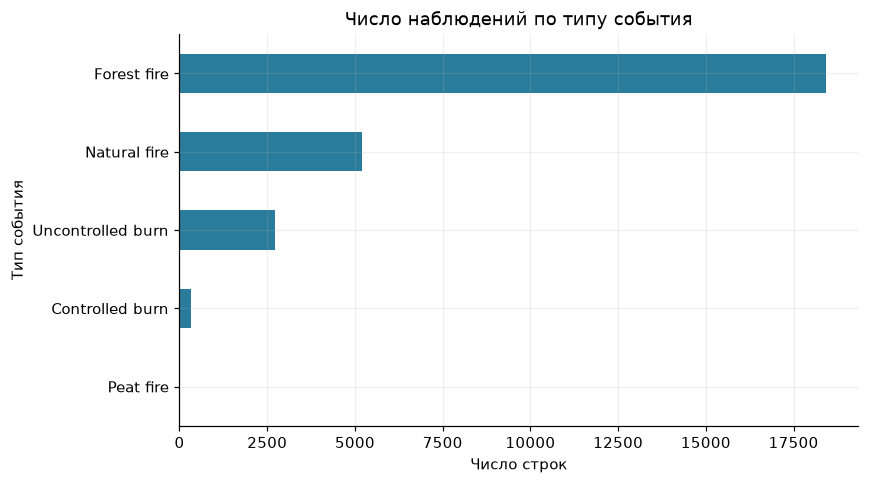

In [96]:
ax = df.type_name.value_counts().sort_values().plot.barh(figsize=(8, 4.5), color='#297c9b')
ax.set(title='Число наблюдений по типу события', xlabel='Число строк', ylabel='Тип события')
plt.tight_layout()
plt.show()

На графике виден сильный перевес Forest fire. При сравнении категорий нужно учитывать их разные размеры; общий показатель качества классификации может скрывать слабую работу на редких категориях.

### 9.2. Распределение температуры

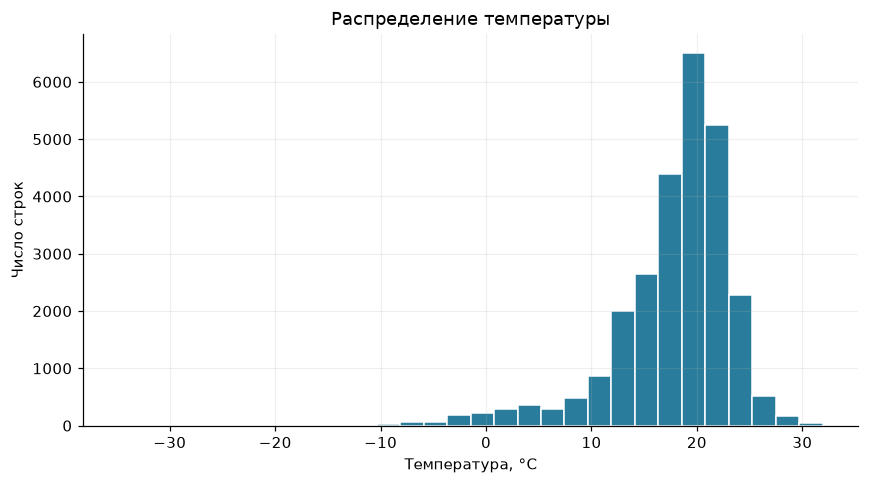

In [97]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(df.temperature_c, bins=30, edgecolor='white', color='#297c9b')
ax.set(title='Распределение температуры', xlabel='Температура, °C', ylabel='Число строк')
plt.tight_layout()
plt.show()

Основная масса значений находится при положительной температуре. Длинный левый хвост требует предметной проверки, а не автоматического удаления отрицательных температур.

### 9.3. Взаимосвязь температуры и влажности

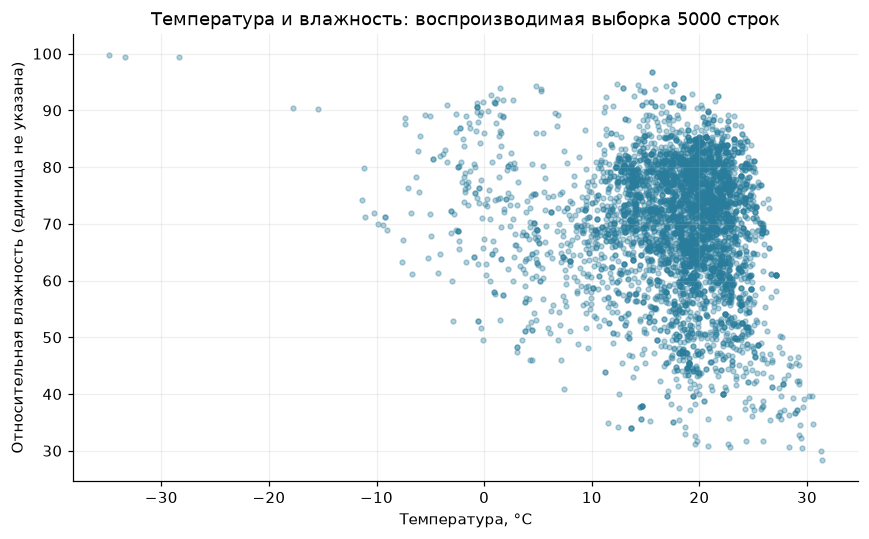

In [98]:
sample = df.sample(n=min(5000, len(df)), random_state=42)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(sample.temperature_c, sample.relative_humidity, s=10, alpha=0.35, color='#297c9b')
ax.set(title='Температура и влажность: воспроизводимая выборка 5000 строк',
       xlabel='Температура, °C', ylabel='Относительная влажность (единица не указана)')
plt.tight_layout()
plt.show()

Облако точек сильно размыто: одна температура не объясняет влажность. Корреляция рассчитана по всем строкам, а подвыборка используется только для читаемости графика.

### 9.4. Пространственное распределение

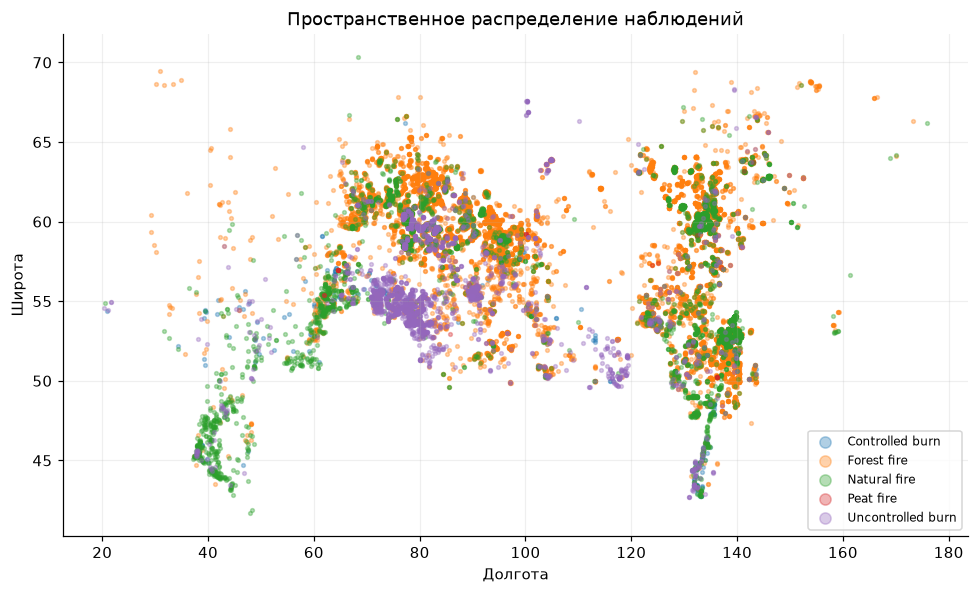

In [99]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for name, part in df.groupby('type_name', observed=True):
    ax.scatter(part.lon, part.lat, s=6, alpha=0.35, label=name)
ax.set(title='Пространственное распределение наблюдений', xlabel='Долгота', ylabel='Широта')
ax.legend(markerscale=3, fontsize=8)
plt.tight_layout()
plt.show()

Точки образуют пространственные скопления, категории частично перекрываются. Это диаграмма координат, а не географическая карта: нет проекции и границ регионов. По плотности точек нельзя судить о риске на единицу площади.

### 10. Экспорт, размеры, скорость чтения и round-trip
Для обоих датасетов используется одна функция. Сохраняется одна и та же таблица:
CSV в UTF-8 без сжатия, JSON Lines без сжатия и Parquet со Snappy. Скорость чтения —
медиана пяти повторов после одного прогрева, поэтому это локальный эксперимент
с файловым кэшем, а не универсальный рейтинг форматов.

In [100]:
def export_and_check(table, stem):
    folder = BASE / 'output'
    folder.mkdir(exist_ok=True)
    paths = {ext: folder / f'{stem}.{ext}' for ext in ['csv', 'json', 'parquet']}
    table.to_csv(paths['csv'], index=False, encoding='utf-8')
    table.to_json(paths['json'], orient='records', lines=True, force_ascii=False,
                  date_format='iso', double_precision=15)
    table.to_parquet(paths['parquet'], index=False, engine='pyarrow', compression='snappy')
    readers = {'csv': lambda: pd.read_csv(paths['csv']),
               'json': lambda: pd.read_json(paths['json'], orient='records', lines=True, convert_dates=False),
               'parquet': lambda: pd.read_parquet(paths['parquet'])}
    returned, records = {}, []
    for ext, reader in readers.items():
        back = reader()
        returned[ext] = back
        assert back.shape == table.shape and back.columns.tolist() == table.columns.tolist()
        # CSV/JSON не сохраняют category и точную схему. Восстанавливаем её для проверки значений.
        restored = back.copy()
        for col in table.columns:
            dtype = table[col].dtype
            if pd.api.types.is_datetime64_any_dtype(dtype):
                restored[col] = pd.to_datetime(restored[col]).astype(dtype)
            elif isinstance(dtype, pd.CategoricalDtype):
                restored[col] = restored[col].astype(dtype)
            else:
                restored[col] = restored[col].astype(dtype)
        pd.testing.assert_frame_equal(table.reset_index(drop=True), restored.reset_index(drop=True),
                                       check_exact=False, rtol=1e-10, atol=1e-10)
        if ext == 'parquet':
            # Числовые category могут читаться как int: проверяем значения после восстановления схемы.
            pd.testing.assert_frame_equal(table.reset_index(drop=True), restored, check_exact=True)
        elapsed = []
        for _ in range(5):
            start = perf_counter()
            reader()
            elapsed.append((perf_counter() - start) * 1000)
        records.append({'формат': ext, 'байт': paths[ext].stat().st_size,
                         'MiB': paths[ext].stat().st_size / 1024**2,
                         'чтение, мс (медиана)': np.median(elapsed),
                         'строк': len(back), 'столбцов': back.shape[1]})
    display(pd.DataFrame(records).set_index('формат').round(3))
    display(pd.DataFrame({'исходный': table.dtypes.astype(str), **{
        ext: back.dtypes.astype(str) for ext, back in returned.items()}}))
    print('Проверены размеры, порядок столбцов и значения всех трёх форматов; типы до и после чтения показаны выше.')
    return pd.DataFrame(records).set_index('формат')

fire_exports = export_and_check(clean_df, 'FiresRu_clean')
display(pd.read_parquet(BASE / 'output/FiresRu_clean.parquet', columns=['type_name', 'temperature_c']).head())

,байт,MiB,"чтение, мс (медиана)",строк,столбцов
формат,,,,,
csv,1827275,1.743,24.343,26681,11
json,7183440,6.851,122.637,26681,11
parquet,635707,0.606,3.718,26681,11


,исходный,csv,json,parquet
type_name,category,str,str,category
type_id,int8,int64,int64,int8
lon,float64,float64,float64,float64
lat,float64,float64,float64,float64
temperature_c,float64,float64,float64,float64
precipitation_mm,float64,float64,float64,float64
relative_humidity,float64,float64,float64,float64
wind_speed_ms,float64,float64,float64,float64
solar_radiation,float64,float64,float64,float64
wind_speed_kmh,float64,float64,float64,float64


Проверены размеры, порядок столбцов и значения всех трёх форматов; типы до и после чтения показаны выше.


,type_name,temperature_c
0,Natural fire,-9.44
1,Natural fire,-9.44
2,Forest fire,-10.71
3,Natural fire,-7.77
4,Natural fire,-9.44


CSV и JSON требуют восстановления категориальных и компактных типов. Parquet сохраняет схему и позволяет читать только нужные столбцы. Сжатие и повторяемость значений влияют на размер; фактические размеры и время приведены выше. Проверка сравнивает значения, а не только количество строк.

### 11. Итог по FiresRu
1. Исходная таблица содержит 26 681 строку и 9 признаков; пропусков и полных дублей нет.
2. Forest fire занимает 69,02% строк, Peat fire — 0,10%; категории несбалансированы.
3. `type_id` является кодом категории; числовое среднее этого поля неинформативно.
4. Оптимизация категорий и кодов сократила память без удаления строк; точная экономия измерена в блоке 6.1.
5. Медиана температуры — 19,08 °C; осадки и скорость ветра имеют длинные правые хвосты.
6. Максимальные по модулю погодные корреляции около 0,30 не подтверждают причинность.
7. IQR выделил 3652 кандидата по ветру; они сохранены для предметной проверки.

**Ограничения:** нет времени и идентификатора отдельного пожара; неизвестна
репрезентативность наблюдений; единицы влажности и солнечной радиации в CSV не
заданы. Выводы относятся только к предоставленному файлу.

## Часть II. Самостоятельная работа: дневной прокат велосипедов
### 12.1. Постановка задачи и источник
**Вопрос:** как различаются суточные объёмы проката при разных погодных условиях
и как они меняются во времени?

Источник: [UCI Bike Sharing](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset),
файл `day.csv`, автор Hadi Fanaee-T, 2013, DOI: [10.24432/C5W894](https://doi.org/10.24432/C5W894).
Дневные агрегаты Capital Bikeshare, Вашингтон, 2011–2012 годы. Скачано 21.09.2026.
На странице UCI указана лицензия **CC BY 4.0**: разрешено использование и
изменение с указанием авторства. Оригинальный `Readme.txt` включён рядом с notebook;
рекомендованная авторами публикация: Fanaee-T и Gama (2013),
[Event labeling combining ensemble detectors and background knowledge](https://doi.org/10.1007/s13748-013-0040-3).

Персональных данных в дневных агрегатах нет. Единица наблюдения — один день,
`cnt` — число аренд, а не число уникальных людей. Датасет выбран самостоятельно,
он отличается от FiresRu и содержит более 500 строк.

In [101]:
BIKE_PATH = BASE / 'day.csv'
print('Заголовок UTF-8:', BIKE_PATH.read_text(encoding='utf-8').splitlines()[0])
bike_raw = pd.read_csv(BIKE_PATH, sep=',', encoding='utf-8')
print('Размер:', bike_raw.shape)
display(bike_raw.head())
bike_raw.info(memory_usage='deep')
display(bike_raw.describe(include='all').T)

Заголовок UTF-8: instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
Размер: (731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344,0.364,0.806,0.160,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363,0.354,0.696,0.249,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196,0.189,0.437,0.248,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200,0.212,0.590,0.160,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.227,0.229,0.437,0.187,82,1518,1600


<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
instant,731.0,NaN,NaN,NaN,366.0,211.166,1.0,183.5,366.0,548.5,731.0
dteday,731,731,2011-01-01,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
season,731.0,NaN,NaN,NaN,2.497,1.111,1.0,2.0,3.0,3.0,4.0
yr,731.0,NaN,NaN,NaN,0.501,0.5,0.0,0.0,1.0,1.0,1.0
mnth,731.0,NaN,NaN,NaN,6.52,3.452,1.0,4.0,7.0,10.0,12.0
holiday,731.0,NaN,NaN,NaN,0.029,0.167,0.0,0.0,0.0,0.0,1.0
weekday,731.0,NaN,NaN,NaN,2.997,2.005,0.0,1.0,3.0,5.0,6.0
workingday,731.0,NaN,NaN,NaN,0.684,0.465,0.0,0.0,1.0,1.0,1.0
weathersit,731.0,NaN,NaN,NaN,1.395,0.545,1.0,1.0,1.0,2.0,3.0
temp,731.0,NaN,NaN,NaN,0.495,0.183,0.059,0.337,0.498,0.655,0.862


### 12.2. Паспорт и словарь полей
Получено 731 наблюдение и 16 столбцов. Разделитель — запятая; UTF-8 прочитан без
ошибок. Дата распознана как строка и требует явного преобразования.

| Поле | Смысл |
|---|---|
| instant | Порядковый идентификатор записи |
| dteday | Дата, YYYY-MM-DD |
| season | Код сезонной категории 1–4 |
| yr | Код года: 0 = 2011, 1 = 2012 |
| mnth | Месяц 1–12 |
| holiday | Признак праздничного дня |
| weekday | День недели, 0 = воскресенье |
| workingday | 1 — рабочий день; 0 — выходной/праздник |
| weathersit | Код погоды 1–4: от ясной/облачной до тяжёлых осадков |
| temp, atemp | Нормированные температура и ощущаемая температура |
| hum | Влажность, нормированная делением на 100 |
| windspeed | Нормированная скорость ветра |
| casual, registered | Аренды незарегистрированных и зарегистрированных пользователей |
| cnt | Общее число аренд за день |

**Неоднозначность метаданных:** названия сезонов в Readme и таблице UCI расходятся.
Поэтому `season` сохраняется как код без спорного перевода. Температура и ветер
анализируются в исходной нормированной шкале, без восстановления физических единиц.

### 12.3. Качество и обоснованная предобработка

In [102]:
display(pd.DataFrame({'dtype': bike_raw.dtypes.astype(str), 'пропусков': bike_raw.isna().sum(),
                      'уникальных': bike_raw.nunique()}))
print('Полных дубликатов:', bike_raw.duplicated().sum())
bike = bike_raw.copy()
bike['dteday'] = pd.to_datetime(bike['dteday'], format='%Y-%m-%d', errors='raise')
bike = bike.sort_values('dteday').reset_index(drop=True)
checks = pd.Series({
    'Повторы дат': bike.dteday.duplicated().sum(),
    'Нарушение cnt = casual + registered': (bike.cnt != bike.casual + bike.registered).sum(),
    'Отрицательные числа аренд': (bike[['cnt', 'casual', 'registered']] < 0).any(axis=1).sum(),
    'Нормированные признаки вне [0, 1]': (~bike[['temp', 'atemp', 'hum', 'windspeed']].ge(0)
                                       | ~bike[['temp', 'atemp', 'hum', 'windspeed']].le(1)).any(axis=1).sum(),
    'Пропущенные даты': len(pd.date_range(bike.dteday.min(), bike.dteday.max()).difference(bike.dteday)),
    'Несогласованные годы': (bike.dteday.dt.year != bike.yr + 2011).sum(),
    'Несогласованные месяцы': (bike.dteday.dt.month != bike.mnth).sum()
})
display(checks)
assert (checks == 0).all()
print('Период:', bike.dteday.min().date(), '—', bike.dteday.max().date())

,dtype,пропусков,уникальных
instant,int64,0,731
dteday,str,0,731
season,int64,0,4
yr,int64,0,2
mnth,int64,0,12
holiday,int64,0,2
weekday,int64,0,7
workingday,int64,0,2
weathersit,int64,0,3
temp,float64,0,499


Полных дубликатов: 0


Повторы дат                            0
Нарушение cnt = casual + registered    0
Отрицательные числа аренд              0
Нормированные признаки вне [0, 1]      0
Пропущенные даты                       0
Несогласованные годы                   0
Несогласованные месяцы                 0
dtype: int64

Период: 2011-01-01 — 2012-12-31


Пропусков, полных дублей и повторов дат нет; все дни периода представлены. Сумма двух типов аренд равна общей. Строки сохранены полностью: искусственное заполнение или удаление здесь не обосновано. Содержательная подготовка состоит в разборе даты, проверке согласованности и типизации категорий.

In [103]:
bike_before = bike.memory_usage(deep=True).sum()
category_cols = ['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit']
for col in category_cols:
    bike[col] = bike[col].astype('category')
for col in ['instant', 'casual', 'registered', 'cnt']:
    bike[col] = pd.to_numeric(bike[col], downcast='integer')
bike_after = bike.memory_usage(deep=True).sum()
display(pd.DataFrame({'этап': ['После разбора даты', 'После оптимизации'],
                      'байт': [bike_before, bike_after]}))
display(bike.dtypes.astype(str).to_frame('dtype'))
display(Markdown(f'Оптимизация уменьшила память на **{(1-bike_after/bike_before)*100:.2f}%**. '
                 'Категориальные коды исключены из непрерывных статистик; float-поля сохранены без понижения точности.'))

,этап,байт
0,После разбора даты,93700
1,После оптимизации,40593


,dtype
instant,int16
dteday,datetime64[us]
season,category
yr,category
mnth,category
holiday,category
weekday,category
workingday,category
weathersit,category
temp,float64


Оптимизация уменьшила память на **56.68%**. Категориальные коды исключены из непрерывных статистик; float-поля сохранены без понижения точности.

### 12.4. Вычисляемые признаки и составной фильтр

In [104]:
bike['humidity_pct'] = bike['hum'] * 100
bike['registered_share'] = bike['registered'] / bike['cnt'].replace(0, np.nan)
display(bike[['dteday', 'hum', 'humidity_pct', 'cnt', 'registered_share']].head())
busy_clear = bike.loc[(bike['weathersit'] == 1) & (bike['cnt'] > 5000),
                     ['dteday', 'weathersit', 'cnt', 'temp']]
display(busy_clear.head())
display(Markdown(f'При погоде категории 1 и числе аренд > 5000 выбрано **{len(busy_clear)} дней** '
                 f'({len(busy_clear)/len(bike):.1%} выборки). Это описательный порог, а не прогноз спроса.'))

,dteday,hum,humidity_pct,cnt,registered_share
0,2011-01-01,0.806,80.583,985,0.664
1,2011-01-02,0.696,69.609,801,0.836
2,2011-01-03,0.437,43.727,1349,0.911
3,2011-01-04,0.590,59.044,1562,0.931
4,2011-01-05,0.437,43.696,1600,0.949


,dteday,weathersit,cnt,temp
119,2011-04-30,1,5312,0.472
140,2011-05-21,1,5805,0.603
153,2011-06-03,1,5312,0.620
154,2011-06-04,1,5342,0.635
163,2011-06-13,1,5020,0.635


При погоде категории 1 и числе аренд > 5000 выбрано **214 дней** (29.3% выборки). Это описательный порог, а не прогноз спроса.

Влажность восстанавливается по документированной формуле `hum × 100`. `registered_share = registered / cnt` — доля аренд зарегистрированных пользователей за день. Нулевой знаменатель дал бы NaN; в данном файле нулевых значений cnt нет. Доля не является долей уникальных людей.

### 12.5. Две группировки и временная агрегация

In [105]:
weather_stats = bike.groupby('weathersit', observed=True).agg(
    days=('cnt', 'size'), mean_rentals=('cnt', 'mean'), median_rentals=('cnt', 'median'),
    std_rentals=('cnt', 'std'), total_rentals=('cnt', 'sum')).round(2)
display(weather_stats)
day_stats = bike.groupby('workingday', observed=True).agg(
    days=('cnt', 'size'), rentals_mean=('cnt', 'mean'), registered_total=('registered', 'sum'),
    rentals_total=('cnt', 'sum'))
day_stats['registered_share_weighted'] = day_stats['registered_total'] / day_stats['rentals_total']
display(day_stats.round(3))
monthly = bike.set_index('dteday').resample('MS').agg(
    rentals_total=('cnt', 'sum'), rentals_per_day=('cnt', 'mean'), days=('cnt', 'size'))
display(monthly)
display(Markdown(f'Наибольшее среднее число аренд у погодной категории **{weather_stats.mean_rentals.idxmax()}**; '
                 f'размеры групп от {weather_stats.days.min():.0f} до {weather_stats.days.max():.0f} дней. '
                 'Сравнение не отделяет влияние погоды от сезона и года.'))

,days,mean_rentals,median_rentals,std_rentals,total_rentals
weathersit,,,,,
1,463,4876.79,4844.0,1879.48,2257952
2,247,4035.86,4040.0,1809.11,996858
3,21,1803.29,1817.0,1240.28,37869


,days,rentals_mean,registered_total,rentals_total,registered_share_weighted
workingday,,,,,
0,231,4330.169,683537,1000269,0.683
1,500,4584.820,1989125,2292410,0.868


,rentals_total,rentals_per_day,days
dteday,,,
2011-01-01,38189,1231.903,31
2011-02-01,48215,1721.964,28
2011-03-01,64045,2065.968,31
2011-04-01,94870,3162.333,30
2011-05-01,135821,4381.323,31
2011-06-01,143512,4783.733,30
2011-07-01,141341,4559.387,31
2011-08-01,136691,4409.387,31
2011-09-01,127418,4247.267,30


Наибольшее среднее число аренд у погодной категории **1**; размеры групп от 21 до 463 дней. Сравнение не отделяет влияние погоды от сезона и года.

Взвешенная доля зарегистрированных рассчитана через отношение суммарных аренд, а не среднее дневных долей. Для месяцев приведены и сумма, и среднее за день: месяцы различаются по продолжительности. Рабочие и нерабочие дни сравниваются по среднему, а не по суммам групп разной величины.

### 12.6. Числовые признаки, корреляция и потенциальные выбросы

In [106]:
numeric_cols = ['cnt', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered']
display(bike[numeric_cols].describe().T.round(3))
bike_corr = bike[['cnt', 'temp', 'hum', 'windspeed']].corr()
display(bike_corr.round(3))
outlier_rows = []
for col in ['cnt', 'temp', 'windspeed']:
    q1_b, q3_b = bike[col].quantile([0.25, 0.75])
    spread = q3_b - q1_b
    lo, hi = q1_b - 1.5 * spread, q3_b + 1.5 * spread
    flagged = (bike[col] < lo) | (bike[col] > hi)
    outlier_rows.append({'признак': col, 'Q1': q1_b, 'Q3': q3_b, 'нижняя': lo,
                         'верхняя': hi, 'кандидатов': int(flagged.sum()), 'доля': flagged.mean()})
display(pd.DataFrame(outlier_rows).set_index('признак'))

,count,mean,std,min,25%,50%,75%,max
cnt,731.0,4504.349,1937.211,22.000,3152.000,4548.000,5956.000,8714.000
temp,731.0,0.495,0.183,0.059,0.337,0.498,0.655,0.862
atemp,731.0,0.474,0.163,0.079,0.338,0.487,0.609,0.841
hum,731.0,0.628,0.142,0.000,0.520,0.627,0.730,0.972
windspeed,731.0,0.190,0.077,0.022,0.135,0.181,0.233,0.507
casual,731.0,848.176,686.622,2.000,315.500,713.000,1096.000,3410.000
registered,731.0,3656.172,1560.256,20.000,2497.000,3662.000,4776.500,6946.000


,cnt,temp,hum,windspeed
cnt,1.000,0.627,-0.101,-0.235
temp,0.627,1.000,0.127,-0.158
hum,-0.101,0.127,1.000,-0.248
windspeed,-0.235,-0.158,-0.248,1.000


,Q1,Q3,нижняя,верхняя,кандидатов,доля
признак,,,,,,
cnt,3152.000,5956.000,-1054.000,10162.000,0,0.000
temp,0.337,0.655,-0.140,1.133,0,0.000
windspeed,0.135,0.233,-0.012,0.381,13,0.018


Корреляция числа аренд с нормированной температурой ≈ 0,627, с ветром ≈ −0,235, с влажностью ≈ −0,101. Температура и спрос связаны, но сезонность и рост системы могут влиять на оба показателя. IQR — диагностическое правило; помеченные дни сохранены. Связь cnt с casual/registered не интерпретируется как независимая закономерность, поскольку cnt является их суммой.

### 12.7. Четыре визуализации

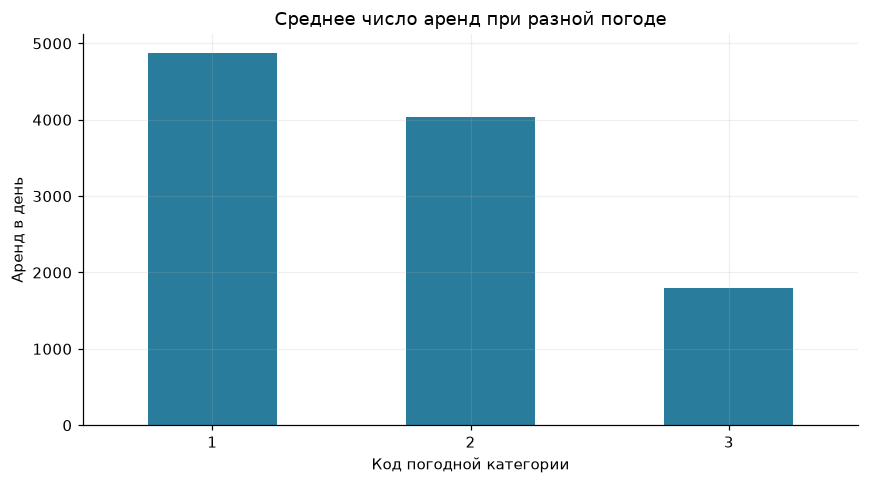

In [107]:
fig, ax = plt.subplots(figsize=(8, 4.5))
weather_stats['mean_rentals'].plot.bar(ax=ax, color='#297c9b', rot=0)
ax.set(title='Среднее число аренд при разной погоде', xlabel='Код погодной категории', ylabel='Аренд в день')
plt.tight_layout()
plt.show()

Среднее число аренд снижается от категории 1 к категории 3. Категория 4 в дневных данных не наблюдается. Различие средних не доказывает, что оно вызвано только погодой.

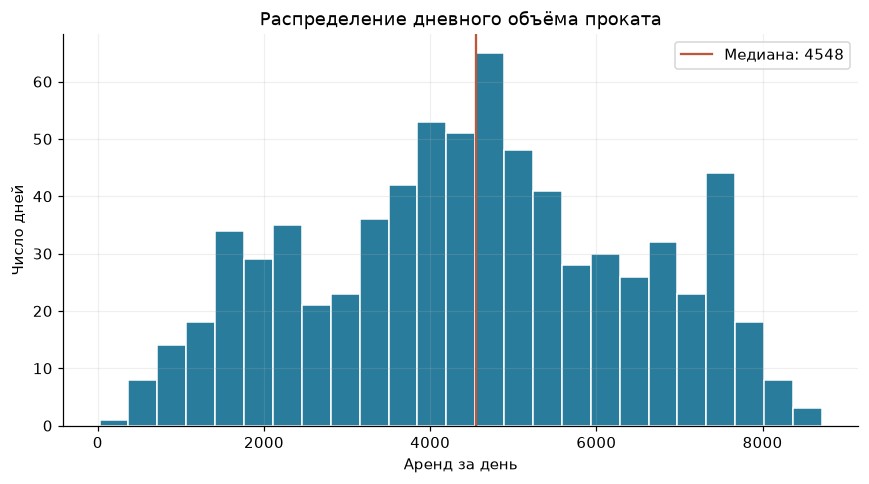

In [108]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(bike.cnt, bins=25, edgecolor='white', color='#297c9b')
ax.axvline(bike.cnt.median(), color='#bd5739', label=f'Медиана: {bike.cnt.median():.0f}')
ax.set(title='Распределение дневного объёма проката', xlabel='Аренд за день', ylabel='Число дней')
ax.legend()
plt.tight_layout()
plt.show()

Распределение широкое: один средний показатель не описывает различия между днями. Гистограмма смешивает сезоны и два года наблюдения, поэтому не является распределением спроса при одинаковых условиях.

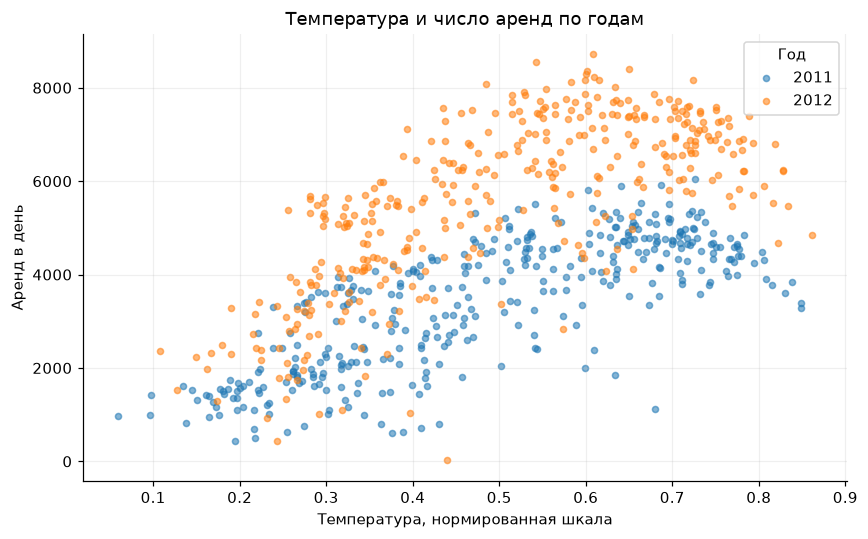

In [109]:
fig, ax = plt.subplots(figsize=(8, 5))
for year, part in bike.groupby(bike.dteday.dt.year):
    ax.scatter(part.temp, part.cnt, s=16, alpha=0.55, label=str(year))
ax.set(title='Температура и число аренд по годам', xlabel='Температура, нормированная шкала', ylabel='Аренд в день')
ax.legend(title='Год')
plt.tight_layout()
plt.show()

При увеличении температуры спрос в целом растёт, но облако не лежит на прямой. Цвет по годам помогает увидеть, что межгодовые различия также участвуют в общей корреляции.

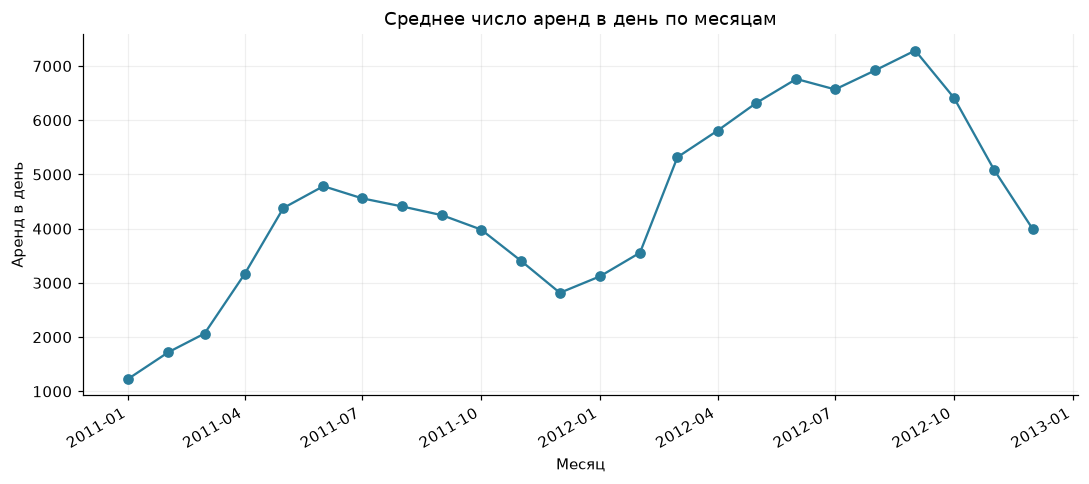

In [110]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(monthly.index, monthly.rentals_per_day, marker='o', color='#297c9b')
ax.set(title='Среднее число аренд в день по месяцам', xlabel='Месяц', ylabel='Аренд в день')
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

Во временном ряду видны подъёмы в тёплую часть года и более высокий уровень 2012 года. Агрегация по среднему за день устраняет прямой эффект разного числа дней в месяцах. Двух лет недостаточно для устойчивой оценки многолетней сезонности.

### 12.8. Экспорт и проверка повторного чтения

In [111]:
bike_exports = export_and_check(bike, 'BikeSharing_clean')

,байт,MiB,"чтение, мс (медиана)",строк,столбцов
формат,,,,,
csv,78946,0.075,2.393,731,18
json,225727,0.215,4.842,731,18
parquet,63918,0.061,1.937,731,18


,исходный,csv,json,parquet
instant,int16,int64,int64,int16
dteday,datetime64[us],str,str,datetime64[us]
season,category,int64,int64,int64
yr,category,int64,int64,int64
mnth,category,int64,int64,int64
holiday,category,int64,int64,int64
weekday,category,int64,int64,int64
workingday,category,int64,int64,int64
weathersit,category,int64,int64,int64
temp,float64,float64,float64,float64


Проверены размеры, порядок столбцов и значения всех трёх форматов; типы до и после чтения показаны выше.


Для сравнения форматов сохранены одинаковые строки и столбцы. CSV/JSON восстанавливают схему частично: дату и категории приходится приводить явно. Parquet сохранил дату и компактные числовые типы, но числовые категории вернулись как целые числа. Их категориальный dtype восстановлен явно по исходной схеме; это особенность используемой связки pandas/pyarrow. Все значения проверены после обратного чтения; файлы доступны в `output`.

### 12.9. Итог самостоятельного анализа

In [112]:
yearly = bike.groupby(bike.dteday.dt.year)['cnt'].sum()
growth = (yearly.loc[2012] / yearly.loc[2011] - 1) * 100
best_month = monthly.rentals_per_day.idxmax()
reg_share = bike.registered.sum() / bike.cnt.sum()
display(Markdown(f"""
1. В таблице **{len(bike)} дней**, с {bike.dteday.min():%d.%m.%Y} по {bike.dteday.max():%d.%m.%Y}; пропусков и полных дубликатов нет.
2. Среднее число аренд — **{bike.cnt.mean():.1f}** в день, медиана — **{bike.cnt.median():.0f}**; диапазон от **{bike.cnt.min()}** до **{bike.cnt.max()}**.
3. В 2011 году зафиксировано **{yearly.loc[2011]:,}** аренд, в 2012 — **{yearly.loc[2012]:,}**: рост **{growth:.1f}%**. Это наблюдаемый рост объёма, его причины не установлены.
4. Наиболее высокий средний дневной объём за месяц — **{monthly.rentals_per_day.max():.1f}**, месяц **{best_month:%Y-%m}**.
5. Корреляция температуры и числа аренд составляет **{bike_corr.loc['temp', 'cnt']:.3f}**; это связь, а не оценка причинного эффекта.
6. Зарегистрированные пользователи обеспечили **{reg_share:.1%}** всех аренд. Доля рассчитана по суммам, а не по среднему дневных долей.
7. При погоде категории 1 среднее число аренд равно **{weather_stats.loc[1, 'mean_rentals']:.1f}**, категории 3 — **{weather_stats.loc[3, 'mean_rentals']:.1f}**; группы различаются по объёму и составу.

**Ограничения:**
- Это один город и два исторических года; выводы нельзя автоматически переносить на другие города и текущий спрос.
- Дневная агрегация скрывает часы пик, станции и индивидуальные поездки. Число аренд не равно числу уникальных пользователей.
- Сезон, год, погода и развитие системы смешаны; причинность и будущий спрос не установлены.
- Метаданные кодов сезонов неоднозначны, а температура и ветер оставлены в нормированной шкале.
"""))


1. В таблице **731 дней**, с 01.01.2011 по 31.12.2012; пропусков и полных дубликатов нет.
2. Среднее число аренд — **4504.3** в день, медиана — **4548**; диапазон от **22** до **8714**.
3. В 2011 году зафиксировано **1,243,103** аренд, в 2012 — **2,049,576**: рост **64.9%**. Это наблюдаемый рост объёма, его причины не установлены.
4. Наиболее высокий средний дневной объём за месяц — **7285.8**, месяц **2012-09**.
5. Корреляция температуры и числа аренд составляет **0.627**; это связь, а не оценка причинного эффекта.
6. Зарегистрированные пользователи обеспечили **81.2%** всех аренд. Доля рассчитана по суммам, а не по среднему дневных долей.
7. При погоде категории 1 среднее число аренд равно **4876.8**, категории 3 — **1803.3**; группы различаются по объёму и составу.

**Ограничения:**
- Это один город и два исторических года; выводы нельзя автоматически переносить на другие города и текущий спрос.
- Дневная агрегация скрывает часы пик, станции и индивидуальные поездки. Число аренд не равно числу уникальных пользователей.
- Сезон, год, погода и развитие системы смешаны; причинность и будущий спрос не установлены.
- Метаданные кодов сезонов неоднозначны, а температура и ветер оставлены в нормированной шкале.


## Часть III. Ответы на контрольные вопросы
1. **Почему числовой dtype не гарантирует количественный смысл?** Число может быть кодом класса, как `type_id`. Арифметика над такими кодами зависит от произвольной нумерации.
2. **DataFrame и ndarray:** обычный NumPy ndarray имеет общий dtype элементов; DataFrame — имена столбцов, индекс и отдельный dtype каждого столбца. У NumPy также существуют структурированные массивы, но здесь сравнивается обычный однородный массив.
3. **head, info, describe:** head показывает примеры, info — схему, заполненность и память, describe — сводные статистики. Ни одна функция не заменяет все проверки.
4. **Почему отсутствие пропусков и дублей недостаточно?** Возможны неверные единицы, невозможные значения, несогласованные коды, смещение выборки и ошибки источника.
5. **Когда полезен category?** Когда много повторяющихся значений и мало уникальных: вместо повторных строк хранятся компактные коды и словарь. При высокой уникальности выигрыш не гарантирован.
6. **Фильтрация и группировка:** фильтр выбирает строки по условию, группировка объединяет строки по ключу для расчёта статистик.
7. **Корреляция около нуля:** нет выраженной линейной связи. Нелинейная зависимость, влияние третьих факторов и связь внутри отдельных групп могут сохраняться.
8. **Почему IQR не удаляет автоматически?** Оно выделяет необычные относительно квартилей значения, которые могут быть реальными, особенно при асимметрии распределения.
9. **Выбор графика:** histogram — распределение числового поля; bar chart — сравнение категорий; scatter — связь двух числовых полей; временной ряд — динамика по настоящему времени.
10. **Почему индекс не заменяет дату?** Номер строки отражает порядок хранения, а не время события или длительность интервала. Приписывание ему времени создаёт вымышленную динамику.
11. **Преимущества Parquet:** схема типов, сжатие, колоночное хранение, чтение нужных столбцов; для CSV нужны повторный разбор текста и восстановление типов. Выигрыш скорости зависит от задачи и размера файла.
12. **Зачем Restart + Run All?** Это проверяет отсутствие скрытых переменных и зависимостей от ручного порядка запуска. Другой человек должен получить результаты из исходных файлов последовательным выполнением ячеек.

## Заключение
Выполнен полный цикл анализа двух наборов: от проверки исходных файлов до
проверенного экспорта. Наблюдения не удалялись без обоснования; категориальные коды
отделены от количественных признаков, выводы сопровождаются ограничениями.